# Basics of Mobile Robotics - Project

#### Students:
ADD NAMES

In [52]:
%reload_ext autoreload
%autoreload 2

import sys
import tdmclient.notebook


sys.path.append('./src')

import filtering
import global_navigation
import local_navigation
import vision
from robot import Robot

#### Connect to and define functions

In [53]:
await tdmclient.notebook.start()
print("Connected to Thymio")

Connected to Thymio


In [54]:
@tdmclient.notebook.sync_var
def robot_set_speed(left, right):
    global motor_left_target, motor_right_target
    motor_left_target = left
    motor_right_target = right

@tdmclient.notebook.sync_var
def robot_stop():
    global motor_left_target,motor_right_target
    motor_left_target = 0
    motor_right_target = 0
    
@tdmclient.notebook.sync_var
def robot_get_speed():
    global motor_left_speed, motor_right_speed
    return motor_left_speed, motor_right_speed
    
@tdmclient.notebook.sync_var
def robot_get_ir():
    global prox_horizontal
    return prox_horizontal.copy()

@tdmclient.notebook.sync_var
def robot_get_acc():
    global acc
    return acc

In [55]:
%%run_python



#### Create robot, pass functions and test

In [56]:
robot = Robot(robot_set_speed, robot_stop, robot_get_speed, robot_get_ir, robot_get_acc)

In [65]:
vs, pos, Ps = robot.try_kalman()

Predict step with v: 0.0, w: 0.0, dt: 0.2
Predict step with v: 0.0, w: 0.0, dt: 0.2
Predict step with v: 53.4681, w: 0.02119787234042549, dt: 0.2
Predict step with v: 64.26135, w: 0.0529946808510638, dt: 0.2
Predict step with v: 65.0916, w: 0.07772553191489358, dt: 0.2
Predict step with v: 67.91445, w: 0.06712659574468084, dt: 0.2
Predict step with v: 66.08789999999999, w: 0.04239574468085113, dt: 0.2
Predict step with v: 65.0916, w: -0.08479148936170218, dt: 0.2
Predict step with v: 65.0916, w: 0.028263829787234084, dt: 0.2
Predict step with v: 65.0916, w: 0.0, dt: 0.2
Predict step with v: 67.25025, w: -0.04592872340425535, dt: 0.2
Predict step with v: 66.25395, w: 0.003532978723404223, dt: 0.2
Predict step with v: 68.0805, w: -0.03532978723404253, dt: 0.2
Predict step with v: 68.91075000000001, w: -0.003532978723404374, dt: 0.2
Predict step with v: 68.57865000000001, w: -0.01059893617021282, dt: 0.2
Predict step with v: 67.0842, w: 0.03532978723404253, dt: 0.2
Predict step with v: 67

In [48]:
robot.stop()

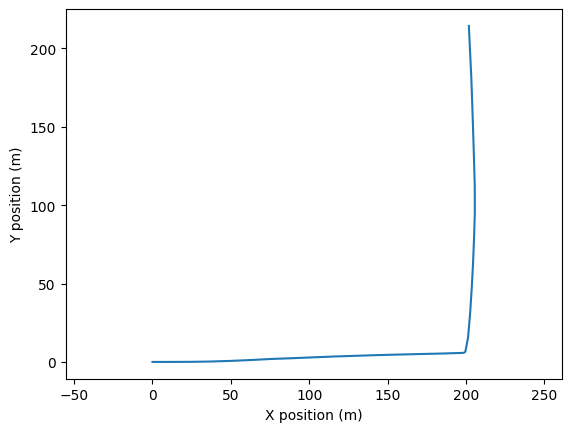

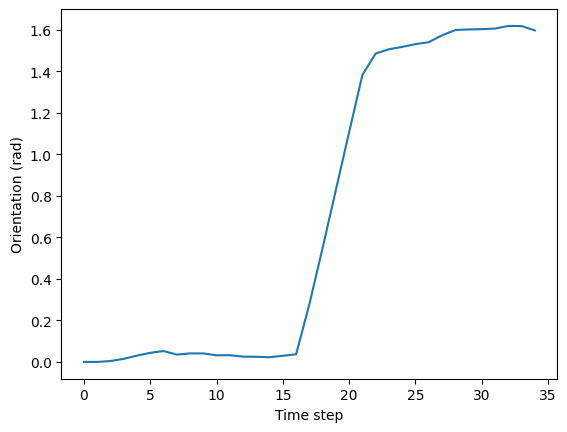

In [66]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot([p[0] for p in pos], [p[1] for p in pos], label='Estimated Path')
plt.axis('equal')
plt.xlabel('X position (m)')
plt.ylabel('Y position (m)')
plt.show()

plt.figure()
plt.plot([p[2] for p in pos], label='Estimated Orientation')
plt.xlabel('Time step')
plt.ylabel('Orientation (rad)')
plt.show()


#### Create other classes

In [ ]:
kalman = filtering.KalmanFilter()
vision = vision.Vision()
global_nav = global_navigation.GlobalNavigation()
local_nav = local_navigation.LocalNavigation()

#### Disconnect robot

In [25]:
# TODO:
await tdmclient.notebook.stop()
print("Disconnected from Thymio")

Disconnected from Thymio
